# 03 – CatBoost modelio eksperimentai

## Darbo tikslas

Šioje užrašinėje tiriamas **CatBoost regresijos modelis**, skirtas prognozuoti kitos valandos dviračių paklausą $\hat{y}_{t+1}$.

CatBoost vertinamas tokiomis pačiomis sąlygomis kaip ir kiti projekto metodai:

- naudojami tie patys paruošti požymiai;
- naudojami tie patys chronologiniai DEV skaidiniai;
- hiperparametrai parenkami tik pagal DEV rezultatus;
- TEST rinkinys šiame etape nenaudojamas;
- naudojamos tos pačios MAE, RMSE, Peak MAE ir PUR metrikos.

Tikslas nėra iš anksto teigti, kad CatBoost yra geriausias metodas. Eksperimentu tikrinama, kokį rezultatą jis pasiekia tomis pačiomis vertinimo sąlygomis ir kaip jo rezultatas skiriasi nuo sezoninio atskaitos metodo.

## Kodėl pasirinktas CatBoost metodas?

CatBoost yra **gradientinio stiprinimo (gradient boosting)** metodas, kuriame galutinė prognozė sudaroma nuosekliai jungiant sprendimų medžius. Kiekvienas naujas medis papildo ankstesnių medžių sudarytą modelį.

Šiame darbe CatBoost pasirinktas kaip vienas iš intelektualiųjų regresijos metodų, nes dviračių paklausos uždavinyje naudojami skirtingo pobūdžio laiko, kalendoriniai, meteorologiniai ir ankstesnės paklausos požymiai, o medžiais pagrįstas modelis gali modeliuoti netiesinius jų tarpusavio ryšius.

CatBoost rezultatas bus vertinamas ne vien pagal vieną metriką, bet ir pagal palyginimą su sezoniniu atskaitos metodu, prognozių grafiką, piko metrikas, požymių svarbą ir konkrečias didžiausias klaidas.

## 1. Gradientinio stiprinimo principas ir ryšys su programiniu kodu

Bendrą gradientinio stiprinimo principą galima užrašyti:

$$
F_M(x)
=
F_0(x)
+
\sum_{m=1}^{M}
\eta h_m(x)
$$

čia:

- $F_M(x)$ – galutinė modelio prognozė;
- $F_0(x)$ – pradinė prognozė;
- $M$ – nuosekliai kuriamų medžių skaičius;
- $\eta$ – mokymosi sparta;
- $h_m(x)$ – $m$-ojo medžio indėlis į bendrą prognozę;
- $x$ – modelio įvesties požymiai.

Ši formulė pateikiama kaip **gradientinio stiprinimo principo formulė**, o ne kaip viso CatBoost algoritmo pilnas matematinis aprašymas.

Ryšys su naudojamu kodu:

- `iterations` nusako kuriamų medžių skaičių $M$;
- `learning_rate` nusako mokymosi spartą $\eta$;
- `depth` nusako vieno medžio gylį;
- `l2_leaf_reg` valdo lapų reikšmių L2 reguliarizaciją;
- `random_strength` ir `bagging_temperature` valdo papildomą modelio atsitiktinumą;
- `loss_function="RMSE"` nurodo mokymo metu optimizuojamą nuostolio funkciją;
- `random_seed=SEED` naudojamas eksperimento atkuriamumui.

CatBoost atveju požymių standartizavimas, kaip MLP modelyje, nėra atliekamas, nes sprendimų medžiai skaidymus formuoja pagal požymių reikšmių ribas, o ne pagal jų bendrą skaitinį mastelį.

In [1]:
from IPython.display import display, Markdown
from pathlib import Path
import sys, warnings, json
warnings.filterwarnings("ignore")
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
DATA_PATH = ROOT / "hour.csv"
RESULTS = ROOT / "results"
RESULTS.mkdir(exist_ok=True)
from src.common import *
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import ParameterGrid
work=load_prepare(DATA_PATH)
FEATURES=feature_columns(work)
dev,test=split_dev_test(work)
folds=rolling_origin_folds(dev)

from catboost import CatBoostRegressor

## 2. Eksperimento korektiškumo kontrolė

CatBoost gauna tą pačią chronologinę DEV struktūrą ir tuos pačius leistinus požymius kaip kiti palyginami modeliai.

Svarbiausios sąlygos:

- `casual` ir `registered` nėra modelio įvesties požymiai;
- tikslas yra vėlesnės valandos paklausa;
- `lag` ir slenkamųjų vidurkių požymiai sudaryti tik iš ankstesnės informacijos;
- kiekviename DEV skaidinyje modelis mokomas iš ankstesnio laikotarpio ir vertinamas vėlesniu laikotarpiu;
- piko slenkstis apskaičiuojamas tik iš konkretaus mokymo skaidinio;
- TEST duomenys hiperparametrų paieškoje nenaudojami.

Tokiu būdu CatBoost vertinamas tomis pačiomis sąlygomis kaip ir kiti projekto metodai.

In [2]:
print("DEV eilučių skaičius:", len(dev))
print("Požymių skaičius:", len(FEATURES))
print("Chronologinių DEV skaidinių skaičius:", len(folds))
print("TEST hiperparametrų paieškai nenaudojamas.")

assert "casual" not in FEATURES
assert "registered" not in FEATURES
assert len(folds) > 0

print("Pagrindinės CatBoost eksperimento sąlygos patikrintos.")

DEV eilučių skaičius: 16295
Požymių skaičius: 17
Chronologinių DEV skaidinių skaičius: 3
TEST hiperparametrų paieškai nenaudojamas.
Pagrindinės CatBoost eksperimento sąlygos patikrintos.


## 3. CatBoost modelio funkcija

Toliau apibrėžiama viena CatBoost kūrimo funkcija. Tokiu būdu visos hiperparametrų konfigūracijos mokomos vienoda programine logika, keičiant tik tiriamus parametrus.

Tiriami:

- `depth` – medžio gylis;
- `iterations` – medžių skaičius;
- `lr` (`learning_rate`) – mokymosi sparta.

Fiksuota `SEED` reikšmė padeda išlaikyti eksperimento atkuriamumą.

In [3]:
def make_cat(depth=7, iterations=500, lr=0.05,
             l2_leaf_reg=None, random_strength=None, bagging_temperature=None):
    params = {
        "depth": depth,
        "iterations": iterations,
        "learning_rate": lr,
        "loss_function": "RMSE",
        "verbose": False,
        "random_seed": SEED,
        "allow_writing_files": False
    }
    if l2_leaf_reg is not None:
        params["l2_leaf_reg"] = l2_leaf_reg
    if random_strength is not None:
        params["random_strength"] = random_strength
    if bagging_temperature is not None:
        params["bagging_temperature"] = bagging_temperature
    return CatBoostRegressor(**params)

def eval_cfg(cfg):
    out=[]
    for tri,vai in folds:
        tr,va=dev.iloc[tri],dev.iloc[vai]
        m=make_cat(**cfg); m.fit(tr[FEATURES],tr["target"])
        p=m.predict(va[FEATURES])
        out.append(metrics(va["target"],p,float(tr["target"].quantile(PEAK_Q))))
    return pd.DataFrame(out).mean(numeric_only=True)
initial={"depth":7,"iterations":500,"lr":0.05}
display(eval_cfg(initial).to_frame("Pradinis CatBoost"))

,Pradinis CatBoost
MAE,36.667554
RMSE,56.010681
Peak_MAE,62.030001
PUR,0.735441
N,720.000000
N_peak,152.000000


## 4. CatBoost hiperparametrų paieška DEV rinkinyje

Atliekama sisteminė riboto tinklelio paieška (**grid search**). Tikrinami keli `depth`, `iterations` ir `learning_rate` deriniai.

Kiekviena konfigūracija vertinama tais pačiais trimis chronologiniais DEV skaidiniais. Pagrindinis konfigūracijos parinkimo kriterijus – **MAE**.

$$
\mathrm{MAE}
=
\frac{1}{N}
\sum_{i=1}^{N}
\left|y_i-\hat{y}_i\right|
$$

čia:

- $y_i$ – faktinė dviračių paklausa;
- $\hat{y}_i$ – CatBoost prognozuota paklausa;
- $N$ – vertinamų stebėjimų skaičius.

Mažesnė MAE reikšmė yra geresnė. Kartu pateikiamos RMSE, Peak MAE ir PUR metrikos, kad modelis būtų vertinamas ne tik pagal vidutinę absoliučią klaidą.

Ši paieška nėra vadinama Bajeso optimizavimu – kode naudojamas konkretus iš anksto sudarytas parametrų tinklelis.

CatBoost konfigūracija 1/18: {'depth': 5, 'iterations': 300, 'lr': 0.03}
  MAE=51.864, RMSE=76.154
CatBoost konfigūracija 2/18: {'depth': 5, 'iterations': 300, 'lr': 0.05}
  MAE=44.389, RMSE=66.071
CatBoost konfigūracija 3/18: {'depth': 5, 'iterations': 500, 'lr': 0.03}
  MAE=44.304, RMSE=66.132
CatBoost konfigūracija 4/18: {'depth': 5, 'iterations': 500, 'lr': 0.05}
  MAE=40.072, RMSE=60.291
CatBoost konfigūracija 5/18: {'depth': 5, 'iterations': 700, 'lr': 0.03}
  MAE=41.130, RMSE=61.951
CatBoost konfigūracija 6/18: {'depth': 5, 'iterations': 700, 'lr': 0.05}
  MAE=38.442, RMSE=58.111
CatBoost konfigūracija 7/18: {'depth': 7, 'iterations': 300, 'lr': 0.03}
  MAE=43.048, RMSE=64.661
CatBoost konfigūracija 8/18: {'depth': 7, 'iterations': 300, 'lr': 0.05}
  MAE=38.629, RMSE=58.662
CatBoost konfigūracija 9/18: {'depth': 7, 'iterations': 500, 'lr': 0.03}
  MAE=38.409, RMSE=58.708
CatBoost konfigūracija 10/18: {'depth': 7, 'iterations': 500, 'lr': 0.05}
  MAE=36.668, RMSE=56.011
CatBoost 

,depth,iterations,lr,MAE,RMSE,Peak_MAE,PUR,N,N_peak
0,9,700,0.05,34.643171,54.028584,58.238970,0.720668,720.0,152.0
1,9,500,0.05,34.997098,54.544831,58.869881,0.719686,720.0,152.0
2,9,700,0.03,35.168977,54.775998,60.150873,0.721649,720.0,152.0
3,7,700,0.05,35.782488,55.166978,59.972702,0.727870,720.0,152.0
4,9,500,0.03,36.047908,55.834038,62.016415,0.736097,720.0,152.0
5,9,300,0.05,36.153375,55.889541,61.124656,0.738468,720.0,152.0
6,7,700,0.03,36.649081,56.371805,62.359873,0.736829,720.0,152.0
7,7,500,0.05,36.667554,56.010681,62.030001,0.735441,720.0,152.0
8,7,500,0.03,38.408670,58.708244,66.435305,0.759637,720.0,152.0
9,5,700,0.05,38.441920,58.111092,65.736805,0.743571,720.0,152.0


Užfiksuota CatBoost konfigūracija: {'depth': 9, 'iterations': 700, 'lr': 0.05}


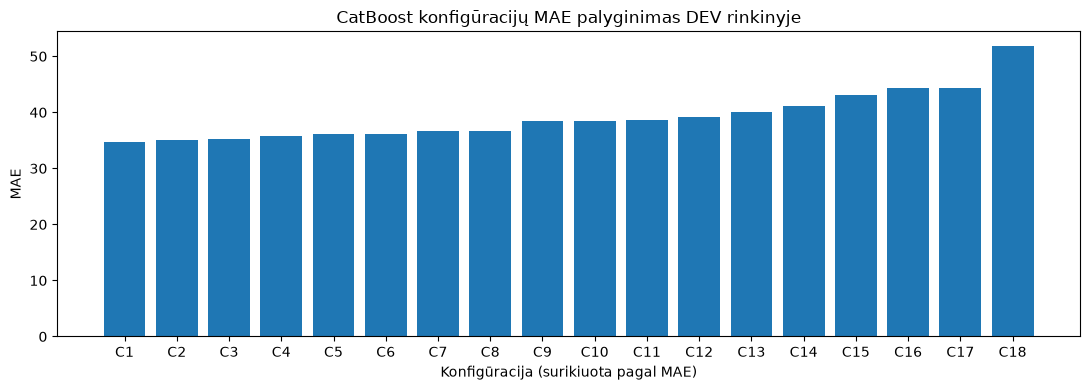

In [4]:
grid=list(ParameterGrid({
 "depth":[5,7,9],
 "iterations":[300,500,700],
 "lr":[0.03,0.05]
}))
rows=[]
for i,cfg in enumerate(grid,1):
    print(f"CatBoost konfigūracija {i}/{len(grid)}: {cfg}")
    r=eval_cfg(cfg)
    rows.append({**cfg,**r.to_dict()})
    print(f"  MAE={r['MAE']:.3f}, RMSE={r['RMSE']:.3f}")

res=pd.DataFrame(rows).sort_values(["MAE","RMSE"]).reset_index(drop=True)
display(res)
best_cat={k:(int(res.iloc[0][k]) if k in ["depth","iterations"] else float(res.iloc[0][k])) for k in ["depth","iterations","lr"]}
print("Užfiksuota CatBoost konfigūracija:",best_cat)
(ROOT/"results"/"best_catboost.json").write_text(json.dumps(best_cat,indent=2),encoding="utf-8")

plt.figure(figsize=(11,4))
plt.bar([f"C{i+1}" for i in range(len(res))],res["MAE"])
plt.title("CatBoost konfigūracijų MAE palyginimas DEV rinkinyje")
plt.xlabel("Konfigūracija (surikiuota pagal MAE)")
plt.ylabel("MAE")
plt.tight_layout()
plt.show()

,depth,iterations,lr,MAE,RMSE,Peak_MAE,PUR,N,N_peak
0,9,700,0.05,34.643171,54.028584,58.238970,0.720668,720.0,152.0
1,9,500,0.05,34.997098,54.544831,58.869881,0.719686,720.0,152.0
2,9,700,0.03,35.168977,54.775998,60.150873,0.721649,720.0,152.0
3,7,700,0.05,35.782488,55.166978,59.972702,0.727870,720.0,152.0
4,9,500,0.03,36.047908,55.834038,62.016415,0.736097,720.0,152.0
5,9,300,0.05,36.153375,55.889541,61.124656,0.738468,720.0,152.0
6,7,700,0.03,36.649081,56.371805,62.359873,0.736829,720.0,152.0
7,7,500,0.05,36.667554,56.010681,62.030001,0.735441,720.0,152.0
8,7,500,0.03,38.408670,58.708244,66.435305,0.759637,720.0,152.0
9,5,700,0.05,38.441920,58.111092,65.736805,0.743571,720.0,152.0



### Geriausia CatBoost konfigūracija pagal DEV MAE

- `depth = 9`
- `iterations = 700`
- `learning_rate = 0.05`
- DEV MAE = **34.643**
- DEV RMSE = **54.029**
- DEV Peak MAE = **58.239**
- DEV PUR = **0.721**

Ši konfigūracija pasirinkta tik pagal DEV rezultatus. TEST duomenys pasirinkimui nenaudoti.


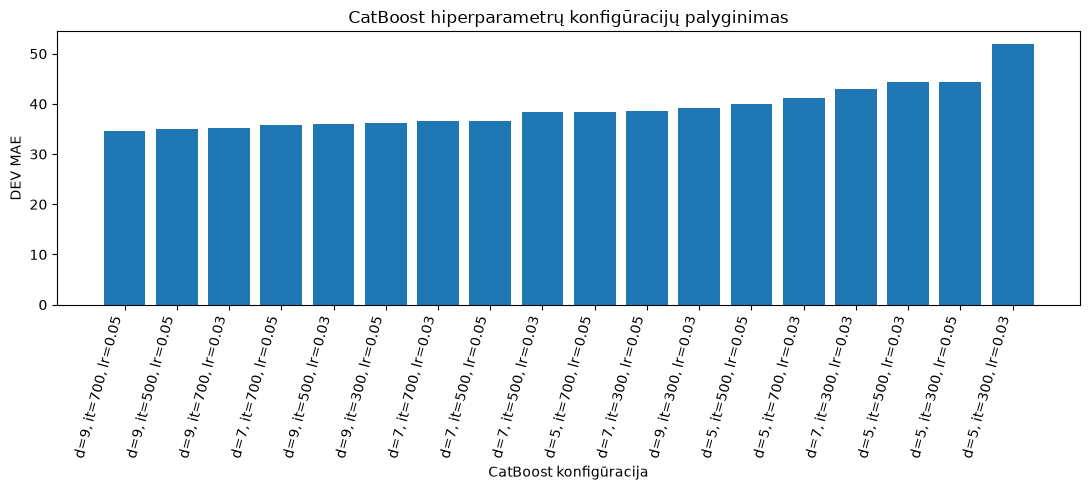

In [5]:
cat_results = pd.DataFrame(rows).sort_values("MAE").reset_index(drop=True)
display(cat_results)

best_row = cat_results.iloc[0]
best_cat = {
    "depth": int(best_row["depth"]),
    "iterations": int(best_row["iterations"]),
    "lr": float(best_row["lr"])
}

display(Markdown(f'''
### Geriausia CatBoost konfigūracija pagal DEV MAE

- `depth = {best_cat["depth"]}`
- `iterations = {best_cat["iterations"]}`
- `learning_rate = {best_cat["lr"]}`
- DEV MAE = **{best_row["MAE"]:.3f}**
- DEV RMSE = **{best_row["RMSE"]:.3f}**
- DEV Peak MAE = **{best_row["Peak_MAE"]:.3f}**
- DEV PUR = **{best_row["PUR"]:.3f}**

Ši konfigūracija pasirinkta tik pagal DEV rezultatus. TEST duomenys pasirinkimui nenaudoti.
'''))

plot_df = cat_results.sort_values("MAE").reset_index(drop=True)
labels = [
    f'd={int(r.depth)}, it={int(r.iterations)}, lr={r.lr:g}'
    for _, r in plot_df.iterrows()
]

plt.figure(figsize=(11, 5))
plt.bar(range(len(plot_df)), plot_df["MAE"])
plt.xticks(range(len(plot_df)), labels, rotation=75, ha="right")
plt.ylabel("DEV MAE")
plt.xlabel("CatBoost konfigūracija")
plt.title("CatBoost hiperparametrų konfigūracijų palyginimas")
plt.tight_layout()
plt.show()

### Hiperparametrų paieškos interpretavimas

Lentelėje paliekamos visos patikrintos konfigūracijos, nes tai parodo, kad galutiniai parametrai nebuvo pasirinkti atsitiktinai.

Tolimesnei analizei naudojama mažiausią vidutinę DEV MAE pasiekusi konfigūracija. Jeigu kelių konfigūracijų rezultatai yra artimi, vien tai nereiškia, kad vienas parametrų derinys būtų universaliai geriausias – išvada taikoma šio eksperimento DEV laikotarpiui ir naudotam parametrų tinkleliui.

## 5. Išsamesnis CatBoost hiperparametrų optimizavimas

Po pradinės tinklelio paieškos atliekamas antras, išsamesnis CatBoost gerinimo etapas. Jo tikslas – kryptingai išnagrinėti platesnę perspektyvių hiperparametrų erdvę.

Naudojama **Optuna TPE (Tree-structured Parzen Estimator)** paieška. Kiekvienas pasiūlytas parametrų derinys vertinamas tais pačiais 3 chronologiniais DEV skaidiniais, o optimizuojamas kriterijus yra vidutinė DEV MAE.

Optimizuojami `depth`, `iterations`, `learning_rate`, `l2_leaf_reg`, `random_strength` ir `bagging_temperature`. Atliekama **40 optimizavimo bandymų**.

Svarbu:

- optimizavimas atliekamas tik DEV;
- TEST duomenys nenaudojami;
- galutinė konfigūracija pasirenkama pagal mažiausią DEV MAE;
- po optimizavimo vis tiek pateikiamos RMSE, Peak MAE ir PUR;
- baigtinis optimizavimo bandymų skaičius negarantuoja teoriškai absoliutaus globalaus optimumo, todėl rezultatas laikomas geriausiu iš šiame eksperimente kryptingai patikrintų variantų.

**Priklausomybė:** galutiniame `requirements.txt` turi būti `optuna>=4.0`.

In [6]:
try:
    import optuna
except ImportError:
    %pip install -q optuna
    import optuna

optuna.logging.set_verbosity(optuna.logging.WARNING)
print("Optuna versija:", optuna.__version__)

Note: you may need to restart the kernel to use updated packages.
Optuna versija: 5.0.0


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
N_TRIALS = 40

first_best_cat = best_cat.copy()
first_best_mae = float(best_row["MAE"])

def objective(trial):
    params = {
        "depth": trial.suggest_int("depth", 4, 10),
        "iterations": trial.suggest_int("iterations", 300, 1000, step=50),
        "lr": trial.suggest_float("learning_rate", 0.015, 0.12, log=True),
        "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 1.0, 15.0, log=True),
        "random_strength": trial.suggest_float("random_strength", 0.0, 2.0),
        "bagging_temperature": trial.suggest_float("bagging_temperature", 0.0, 2.0),
    }

    fold_mae = []
    for tri, vai in folds:
        tr = dev.iloc[tri].copy()
        va = dev.iloc[vai].copy()

        model = make_cat(**params)
        model.fit(tr[FEATURES], tr["target"])
        pred = model.predict(va[FEATURES])

        peak_threshold = float(tr["target"].quantile(PEAK_Q))
        met = metrics(va["target"], pred, peak_threshold)
        fold_mae.append(float(met["MAE"]))

    return float(np.mean(fold_mae))

sampler = optuna.samplers.TPESampler(seed=SEED)
study = optuna.create_study(direction="minimize", sampler=sampler)
study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)

print("Baigta Optuna paieška.")
print("Bandymų skaičius:", len(study.trials))
print("Geriausia Optuna DEV MAE:", round(study.best_value, 3))
display(study.best_params)

  0%|          | 0/40 [00:00<?, ?it/s]

Baigta Optuna paieška.
Bandymų skaičius: 40
Geriausia Optuna DEV MAE: 34.408


{'depth': 9,
 'iterations': 750,
 'learning_rate': 0.04660995625108928,
 'l2_leaf_reg': 2.8353251614835164,
 'random_strength': 0.4621342944162223,
 'bagging_temperature': 0.6308630511001655}

In [8]:
bp = study.best_params
optuna_cat = {
    "depth": int(bp["depth"]),
    "iterations": int(bp["iterations"]),
    "lr": float(bp["learning_rate"]),
    "l2_leaf_reg": float(bp["l2_leaf_reg"]),
    "random_strength": float(bp["random_strength"]),
    "bagging_temperature": float(bp["bagging_temperature"])
}

optuna_fold_rows = []
for fold_id, (tri, vai) in enumerate(folds, 1):
    tr = dev.iloc[tri].copy()
    va = dev.iloc[vai].copy()

    model = make_cat(**optuna_cat)
    model.fit(tr[FEATURES], tr["target"])
    pred = model.predict(va[FEATURES])

    peak_threshold = float(tr["target"].quantile(PEAK_Q))
    met = metrics(va["target"], pred, peak_threshold)
    optuna_fold_rows.append({"fold": fold_id, **met})

optuna_folds = pd.DataFrame(optuna_fold_rows)
display(optuna_folds)
optuna_mean = optuna_folds[["MAE", "RMSE", "Peak_MAE", "PUR"]].mean()

if float(optuna_mean["MAE"]) < first_best_mae:
    best_cat = optuna_cat.copy()
    best_cat_source = "Optuna optimizavimas"
    final_mean = optuna_mean.copy()
    result_text = (
        f"Optuna sumažino vidutinę DEV MAE nuo {first_best_mae:.3f} "
        f"iki {float(optuna_mean['MAE']):.3f}."
    )
else:
    best_cat = first_best_cat.copy()
    best_cat_source = "pradinė tinklelio paieška"
    final_mean = pd.Series({
        "MAE": float(best_row["MAE"]),
        "RMSE": float(best_row["RMSE"]),
        "Peak_MAE": float(best_row["Peak_MAE"]),
        "PUR": float(best_row["PUR"])
    })
    result_text = (
        f"Optuna mažesnės DEV MAE nepasiekė: pradinė MAE buvo {first_best_mae:.3f}, "
        f"o Optuna MAE – {float(optuna_mean['MAE']):.3f}."
    )

display(Markdown(f'''
### Išsamesnio optimizavimo rezultatas

{result_text}

Galutinei CatBoost analizei pasirinktas variantas iš **{best_cat_source}**.

- DEV MAE = **{float(final_mean["MAE"]):.3f}**
- DEV RMSE = **{float(final_mean["RMSE"]):.3f}**
- DEV Peak MAE = **{float(final_mean["Peak_MAE"]):.3f}**
- DEV PUR = **{float(final_mean["PUR"]):.3f}**

TEST duomenys optimizavimo ir galutinės konfigūracijos pasirinkimo metu nenaudoti.
'''))

print("Galutiniai pasirinkti CatBoost parametrai:")
display(best_cat)

,fold,MAE,RMSE,Peak_MAE,PUR,N,N_peak
0,1,35.686108,52.991959,67.385060,0.839806,720,206
1,2,34.050246,55.217347,51.475754,0.690476,720,168
2,3,33.487611,52.991886,61.451724,0.634146,720,82



### Išsamesnio optimizavimo rezultatas

Optuna sumažino vidutinę DEV MAE nuo 34.643 iki 34.408.

Galutinei CatBoost analizei pasirinktas variantas iš **Optuna optimizavimas**.

- DEV MAE = **34.408**
- DEV RMSE = **53.734**
- DEV Peak MAE = **60.104**
- DEV PUR = **0.721**

TEST duomenys optimizavimo ir galutinės konfigūracijos pasirinkimo metu nenaudoti.


Galutiniai pasirinkti CatBoost parametrai:


{'depth': 9,
 'iterations': 750,
 'lr': 0.04660995625108928,
 'l2_leaf_reg': 2.8353251614835164,
 'random_strength': 0.4621342944162223,
 'bagging_temperature': 0.6308630511001655}

,Paieškos etapas,Geriausia DEV MAE
0,Pradinis Grid Search,34.643171
1,Optuna TPE,34.407988


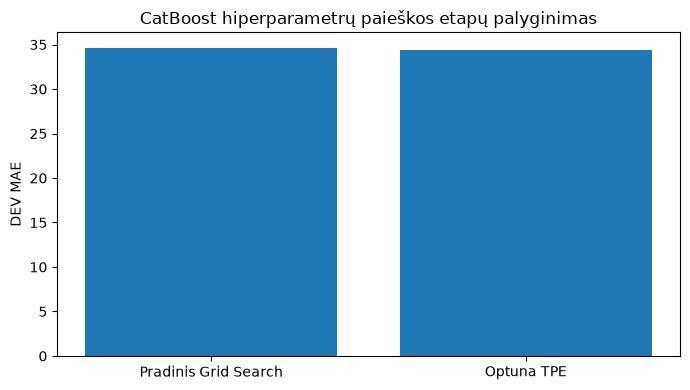

In [9]:
optimization_comparison = pd.DataFrame({
    "Paieškos etapas": ["Pradinis Grid Search", "Optuna TPE"],
    "Geriausia DEV MAE": [first_best_mae, float(optuna_mean["MAE"])]
})
display(optimization_comparison)

plt.figure(figsize=(7, 4))
plt.bar(optimization_comparison["Paieškos etapas"],
        optimization_comparison["Geriausia DEV MAE"])
plt.ylabel("DEV MAE")
plt.title("CatBoost hiperparametrų paieškos etapų palyginimas")
plt.tight_layout()
plt.show()

## 6. Pasirinktos CatBoost konfigūracijos stabilumas DEV skaidiniuose

Vien vidutinė trijų DEV skaidinių metrika gali paslėpti skirtumus tarp laikotarpių. Todėl geriausia konfigūracija dar kartą įvertinama kiekviename chronologiniame skaidinyje atskirai.

Jeigu metrikos tarp skaidinių skiriasi, tai rodo, kad modelio prognozavimo tikslumas priklauso ir nuo vertinamo laikotarpio. Tai ypač svarbu laiko eilutės uždavinyje.

In [10]:
best_fold_rows = []
last_pack = None

for fold_id, (tri, vai) in enumerate(folds, 1):
    tr = dev.iloc[tri].copy()
    va = dev.iloc[vai].copy()

    model = make_cat(**best_cat)
    model.fit(tr[FEATURES], tr["target"])
    pred = model.predict(va[FEATURES])

    peak_threshold = float(tr["target"].quantile(PEAK_Q))
    met = metrics(va["target"], pred, peak_threshold)

    best_fold_rows.append({
        "fold": fold_id,
        **met
    })

    last_pack = {
        "model": model,
        "tr": tr,
        "va": va,
        "pred": pred,
        "peak_threshold": peak_threshold
    }

best_cat_folds = pd.DataFrame(best_fold_rows)
display(best_cat_folds)

display(Markdown(f'''
### Stabilumo santrauka

- MAE vidurkis: **{best_cat_folds["MAE"].mean():.3f}**
- mažiausia skaidinio MAE: **{best_cat_folds["MAE"].min():.3f}**
- didžiausia skaidinio MAE: **{best_cat_folds["MAE"].max():.3f}**

Skirtumas tarp mažiausios ir didžiausios skaidinio MAE parodo, kad modelio rezultatas vertinamas keliuose laikotarpiuose, o ne pagal vieną atsitiktinai pasirinktą validavimo atkarpą.
'''))

,fold,MAE,RMSE,Peak_MAE,PUR,N,N_peak
0,1,35.686108,52.991959,67.385060,0.839806,720,206
1,2,34.050246,55.217347,51.475754,0.690476,720,168
2,3,33.487611,52.991886,61.451724,0.634146,720,82



### Stabilumo santrauka

- MAE vidurkis: **34.408**
- mažiausia skaidinio MAE: **33.488**
- didžiausia skaidinio MAE: **35.686**

Skirtumas tarp mažiausios ir didžiausios skaidinio MAE parodo, kad modelio rezultatas vertinamas keliuose laikotarpiuose, o ne pagal vieną atsitiktinai pasirinktą validavimo atkarpą.


## 7. CatBoost palyginimas su sezoniniu atskaitos metodu DEV rinkinyje

Sudėtingesnio modelio taikymą prasminga vertinti lyginant jį su paprastu sezoniniu atskaitos metodu.

Santykinis MAE pokytis apskaičiuojamas:

$$
\Delta_{\mathrm{MAE}}
=
\frac{
\mathrm{MAE}_{\mathrm{baseline}}
-
\mathrm{MAE}_{\mathrm{CatBoost}}
}{
\mathrm{MAE}_{\mathrm{baseline}}
}
\cdot 100\%
$$

čia:

- $\mathrm{MAE}_{\mathrm{baseline}}$ – sezoninio atskaitos metodo vidutinė DEV MAE;
- $\mathrm{MAE}_{\mathrm{CatBoost}}$ – pasirinkto CatBoost vidutinė DEV MAE;
- $\Delta_{\mathrm{MAE}}$ – santykinis MAE sumažėjimas procentais.

Teigiama reikšmė reiškia mažesnę CatBoost MAE, o neigiama – kad pagal MAE atskaitos metodas nebuvo pagerintas.

,MAE,RMSE,Peak_MAE,PUR
Sezoninis atskaitos metodas,74.240097,123.679354,132.397912,0.538407
CatBoost,34.407988,53.733731,60.104179,0.721476



### Palyginimo rezultatas

- sezoninio atskaitos metodo DEV MAE: **74.24**;
- CatBoost DEV MAE: **34.41**;
- **CatBoost DEV MAE yra 53.7 % mažesnė už sezoninio atskaitos metodo MAE.**

Tai yra DEV palyginimas. Galutinis TEST palyginimas atliekamas tik galutiniame visų modelių vertinimo etape.


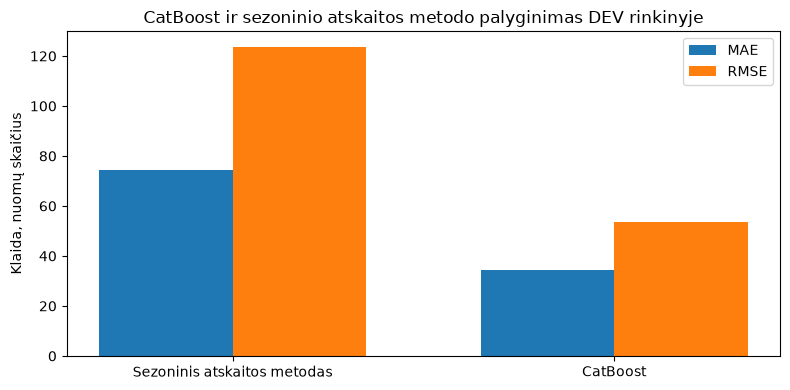

In [11]:
baseline_rows = []

for fold_id, (tri, vai) in enumerate(folds, 1):
    tr = dev.iloc[tri].copy()
    va = dev.iloc[vai].copy()

    baseline_pred = seasonal_baseline(tr, va, k_weeks=4)
    peak_threshold = float(tr["target"].quantile(PEAK_Q))

    baseline_rows.append({
        "fold": fold_id,
        **metrics(va["target"], baseline_pred, peak_threshold)
    })

baseline_folds = pd.DataFrame(baseline_rows)

baseline_mean = baseline_folds[["MAE", "RMSE", "Peak_MAE", "PUR"]].mean()
cat_mean = best_cat_folds[["MAE", "RMSE", "Peak_MAE", "PUR"]].mean()

comparison = pd.DataFrame({
    "Sezoninis atskaitos metodas": baseline_mean,
    "CatBoost": cat_mean
}).T

display(comparison)

mae_change_pct = (
    (baseline_mean["MAE"] - cat_mean["MAE"])
    / baseline_mean["MAE"] * 100
)

if mae_change_pct > 0:
    text_result = f"CatBoost DEV MAE yra {mae_change_pct:.1f} % mažesnė už sezoninio atskaitos metodo MAE."
elif mae_change_pct < 0:
    text_result = f"CatBoost DEV MAE yra {abs(mae_change_pct):.1f} % didesnė už sezoninio atskaitos metodo MAE."
else:
    text_result = "CatBoost ir sezoninio atskaitos metodo DEV MAE sutampa."

display(Markdown(f'''
### Palyginimo rezultatas

- sezoninio atskaitos metodo DEV MAE: **{baseline_mean["MAE"]:.2f}**;
- CatBoost DEV MAE: **{cat_mean["MAE"]:.2f}**;
- **{text_result}**

Tai yra DEV palyginimas. Galutinis TEST palyginimas atliekamas tik galutiniame visų modelių vertinimo etape.
'''))

plot_df = comparison[["MAE", "RMSE"]]
x = np.arange(len(plot_df))
width = 0.35

plt.figure(figsize=(8, 4))
plt.bar(x - width/2, plot_df["MAE"], width, label="MAE")
plt.bar(x + width/2, plot_df["RMSE"], width, label="RMSE")
plt.xticks(x, plot_df.index)
plt.ylabel("Klaida, nuomų skaičius")
plt.title("CatBoost ir sezoninio atskaitos metodo palyginimas DEV rinkinyje")
plt.legend()
plt.tight_layout()
plt.show()

## 8. Faktinės ir prognozuotos paklausos palyginimas

Toliau analizuojamas paskutinis DEV skaidinys. Laiko grafikas leidžia patikrinti, ar CatBoost seka faktinės paklausos kitimą ir kaip elgiasi didesnės paklausos laikotarpiais.

Šis grafikas naudojamas modelio elgsenai paaiškinti, o ne naujiems hiperparametrams parinkti.

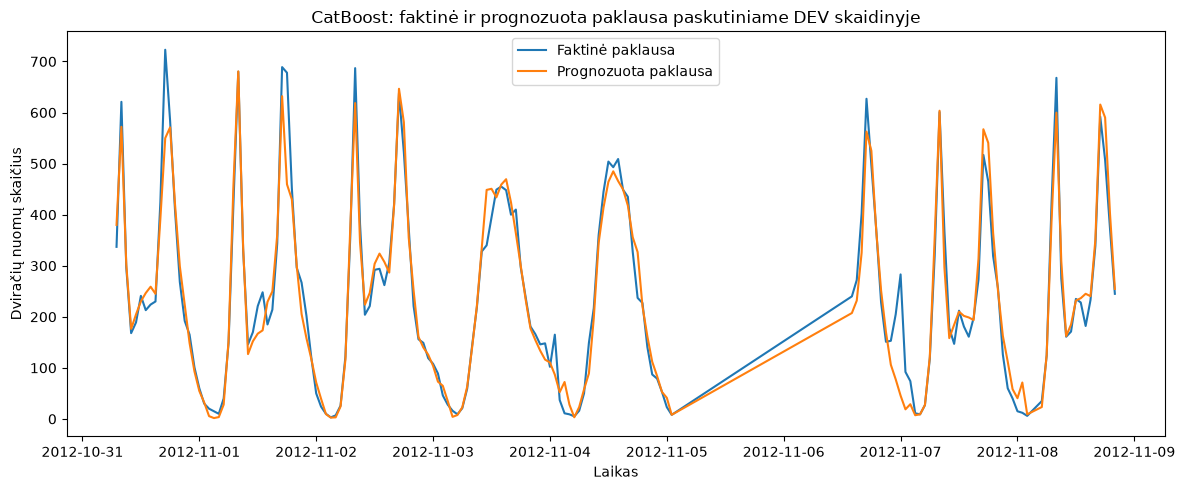

Paskutinio DEV skaidinio metrikos:


,MAE,RMSE,Peak_MAE,PUR,N,N_peak
0,33.487611,52.991886,61.451724,0.634146,720,82


In [12]:
model = last_pack["model"]
tr = last_pack["tr"]
va = last_pack["va"]
pred = last_pack["pred"]
peak_threshold = last_pack["peak_threshold"]

plot_n = min(7 * 24, len(va))
time_axis = va["target_time"].iloc[:plot_n] if "target_time" in va.columns else np.arange(plot_n)

plt.figure(figsize=(12, 5))
plt.plot(time_axis, va["target"].iloc[:plot_n], label="Faktinė paklausa")
plt.plot(time_axis, pred[:plot_n], label="Prognozuota paklausa")
plt.ylabel("Dviračių nuomų skaičius")
plt.xlabel("Laikas")
plt.title("CatBoost: faktinė ir prognozuota paklausa paskutiniame DEV skaidinyje")
plt.legend()
plt.tight_layout()
plt.show()

print("Paskutinio DEV skaidinio metrikos:")
display(pd.DataFrame([metrics(va["target"], pred, peak_threshold)]))

## 9. Faktinės ir prognozuotos paklausos sklaidos diagrama

Idealios prognozės atveju:

$$
\hat{y}_i=y_i
$$

Todėl idealūs taškai būtų ant įstrižainės $\hat{y}=y$. Kuo arčiau šios linijos išsidėsto taškai, tuo mažesnis faktinės ir prognozuotos paklausos skirtumas.

Taškai žemiau idealios linijos reiškia paklausos neįvertinimą, o taškai aukščiau – pervertinimą.

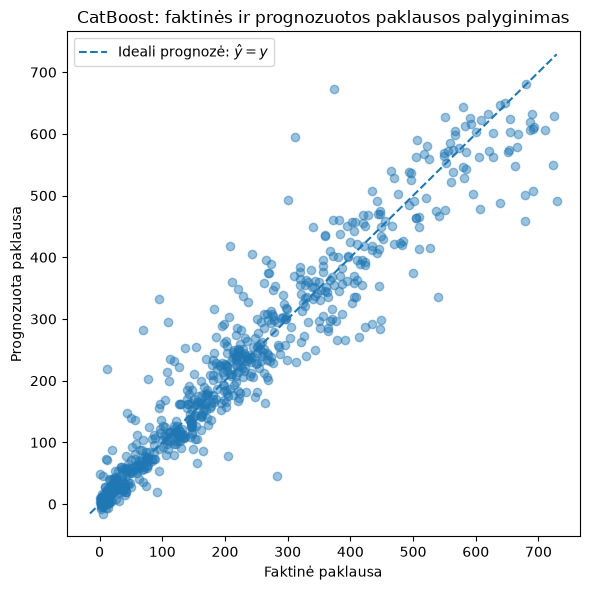

In [13]:
y_true = va["target"].to_numpy()
y_pred = np.asarray(pred)

lower = min(y_true.min(), y_pred.min())
upper = max(y_true.max(), y_pred.max())

plt.figure(figsize=(6, 6))
plt.scatter(y_true, y_pred, alpha=0.45)
plt.plot([lower, upper], [lower, upper], linestyle="--", label=r"Ideali prognozė: $\hat{y}=y$")
plt.xlabel("Faktinė paklausa")
plt.ylabel("Prognozuota paklausa")
plt.title("CatBoost: faktinės ir prognozuotos paklausos palyginimas")
plt.legend()
plt.tight_layout()
plt.show()

## 10. Požymių svarbos analizė

CatBoost leidžia apskaičiuoti modelio naudojamų požymių svarbą. Ji parodo, kurie požymiai turėjo didesnę įtaką konkretaus apmokyto modelio sprendimams.

Svarbu šios reikšmės neinterpretuoti kaip priežastinio ryšio. Didelė požymio svarba reiškia, kad modelis juo aktyviai rėmėsi prognozuodamas, tačiau savaime neįrodo, kad tas požymis yra paklausos pokyčio priežastis.

,Požymis,Svarba
3,hr,47.328767
6,workingday,11.596063
14,lag_168,11.298284
12,lag_1,5.596014
16,rolling_mean_168,4.065391
13,lag_24,3.800245
15,rolling_mean_24,3.656806
7,weathersit,3.614956
8,temp,2.123747
1,yr,1.970572


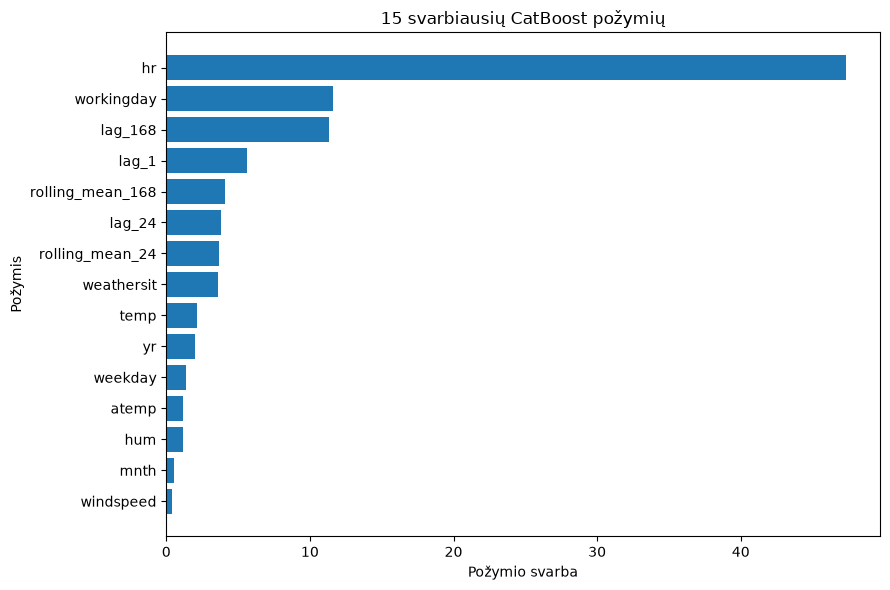

In [14]:
importance = pd.DataFrame({
    "Požymis": FEATURES,
    "Svarba": model.get_feature_importance()
}).sort_values("Svarba", ascending=False)

display(importance.head(15))

top_imp = importance.head(15).sort_values("Svarba")

plt.figure(figsize=(9, 6))
plt.barh(top_imp["Požymis"], top_imp["Svarba"])
plt.xlabel("Požymio svarba")
plt.ylabel("Požymis")
plt.title("15 svarbiausių CatBoost požymių")
plt.tight_layout()
plt.show()

## 11. Prognozavimo paklaidų pasiskirstymas

Pasirašyta prognozavimo paklaida:

$$
e_i
=
y_i-\hat{y}_i
$$

čia:

- $e_i$ – prognozavimo paklaida;
- $y_i$ – faktinė paklausa;
- $\hat{y}_i$ – prognozuota paklausa.

Kai $e_i>0$, modelis paklausą neįvertino. Kai $e_i<0$, modelis paklausą pervertino. Paklaidų pasiskirstymas leidžia patikrinti, ar konkrečiame DEV skaidinyje matomas ryškesnis sisteminis poslinkis į vieną pusę.

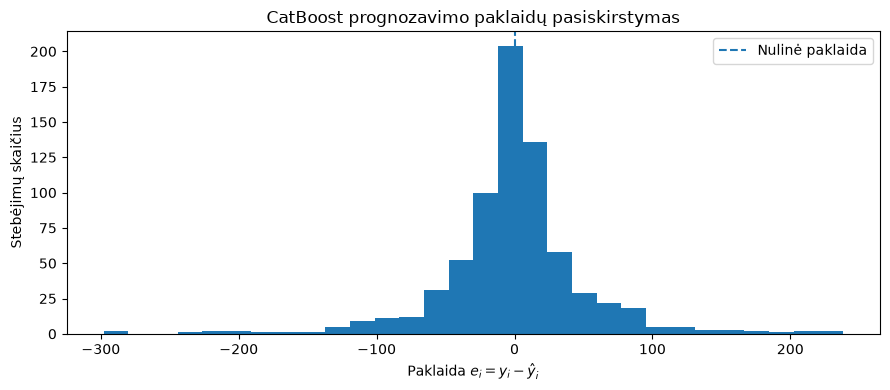


### Paklaidų pasiskirstymo santrauka

- vidutinė pasirašyta paklaida: **-0.31**;
- medianinė pasirašyta paklaida: **-0.04**;
- šiame DEV skaidinyje pagal vidutinės paklaidos ženklą matomas polinkis paklausą pervertinti.

Ši išvada taikoma analizuojamam DEV skaidiniui, o ne galutiniam TEST laikotarpiui.


In [15]:
signed_error = y_true - y_pred

plt.figure(figsize=(9, 4))
plt.hist(signed_error, bins=30)
plt.axvline(0, linestyle="--", label="Nulinė paklaida")
plt.xlabel(r"Paklaida $e_i = y_i - \hat{y}_i$")
plt.ylabel("Stebėjimų skaičius")
plt.title("CatBoost prognozavimo paklaidų pasiskirstymas")
plt.legend()
plt.tight_layout()
plt.show()

mean_error = float(np.mean(signed_error))
median_error = float(np.median(signed_error))

if mean_error > 0:
    direction = "šiame DEV skaidinyje pagal vidutinės paklaidos ženklą matomas polinkis paklausą neįvertinti"
elif mean_error < 0:
    direction = "šiame DEV skaidinyje pagal vidutinės paklaidos ženklą matomas polinkis paklausą pervertinti"
else:
    direction = "vidutinė pasirašyta paklaida šiame DEV skaidinyje lygi nuliui"

display(Markdown(f'''
### Paklaidų pasiskirstymo santrauka

- vidutinė pasirašyta paklaida: **{mean_error:.2f}**;
- medianinė pasirašyta paklaida: **{median_error:.2f}**;
- {direction}.

Ši išvada taikoma analizuojamam DEV skaidiniui, o ne galutiniam TEST laikotarpiui.
'''))

## 12. Didžiausių prognozavimo klaidų analizė

Vien bendros metrikos neparodo, kuriomis valandomis modelis klysta labiausiai. Todėl papildomai pateikiamos didžiausios absoliučios klaidos:

$$
|e_i|
=
|y_i-\hat{y}_i|
$$

Ši lentelė leidžia matyti konkrečius atvejus, kuriuose faktinės ir prognozuotos paklausos skirtumas buvo didžiausias.

In [17]:
errors = va.copy()
errors["Faktinė_paklausa"] = y_true
errors["Prognozuota_paklausa"] = y_pred
errors["Paklaida"] = y_true - y_pred
errors["Absoliuti_klaida"] = np.abs(errors["Paklaida"])

show_cols = [
    c for c in [
        "target_time", "hr", "weekday", "workingday", "weathersit",
        "Faktinė_paklausa", "Prognozuota_paklausa",
        "Paklaida", "Absoliuti_klaida"
    ]
    if c in errors.columns
]

largest_errors = errors.nlargest(10, "Absoliuti_klaida")[show_cols]
display(largest_errors)

,target_time,hr,weekday,workingday,weathersit,Faktinė_paklausa,Prognozuota_paklausa,Paklaida,Absoliuti_klaida
16050,2012-11-21 17:00:00,16,3,1,1,374.0,671.961422,-297.961422,297.961422
16051,2012-11-21 18:00:00,17,3,1,1,311.0,595.551077,-284.551077,284.551077
16089,2012-11-23 08:00:00,7,5,1,1,94.0,332.816300,-238.816300,238.816300
16255,2012-11-30 08:00:00,7,5,1,1,729.0,490.785345,238.214655,238.214655
15700,2012-11-07 00:00:00,23,2,1,1,283.0,45.686306,237.313694,237.313694
15610,2012-11-01 18:00:00,17,4,1,3,678.0,459.433742,218.566258,218.566258
16075,2012-11-22 18:00:00,17,4,0,1,70.0,282.530587,-212.530587,212.530587
16099,2012-11-23 18:00:00,17,5,1,2,208.0,419.044978,-211.044978,211.044978
15867,2012-11-14 01:00:00,0,3,1,1,12.0,218.144430,-206.144430,206.144430
15826,2012-11-12 08:00:00,7,1,0,1,540.0,336.188723,203.811277,203.811277


## 13. Praktinė prognozavimo klaidų reikšmė

Šio uždavinio tikslas nėra vien sumažinti statistinę klaidą. Prognozė gali būti naudojama dviračių dalijimosi sistemos paklausai ir perskirstymo poreikiui planuoti.

Paklausos **neįvertinimas** piko metu gali reikšti, kad numatytas dviračių poreikis yra mažesnis už faktinį. Dėl to šiame darbe kartu su bendromis MAE ir RMSE metrikomis vertinamos Peak MAE ir PUR.

Paklausos **pervertinimas** reiškia, kad prognozuotas poreikis yra didesnis už faktinį.

Šiame darbe šių pasekmių piniginė vertė neskaičiuojama, todėl praktinė interpretacija apsiriboja prognozavimo klaidų kryptimi ir dydžiu.

## 14. CatBoost eksperimento išvada

Šioje užrašinėje:

1. CatBoost susietas su gradientinio stiprinimo principo formule ir konkrečiais programinio kodo parametrais;
2. modelis vertintas tais pačiais chronologiniais DEV skaidiniais ir metrikomis kaip kiti metodai;
3. atlikta pradinė sisteminė `depth`, `iterations` ir `learning_rate` hiperparametrų paieška;
4. atliktas išsamesnis 40 bandymų Optuna TPE optimizavimas, papildomai derinant `l2_leaf_reg`, `random_strength` ir `bagging_temperature`;
5. galutinė CatBoost konfigūracija parenkama tik pagal DEV MAE;
6. TEST duomenys hiperparametrų paieškoje nenaudojami;
7. pasirinktas modelis palyginamas su sezoniniu atskaitos metodu;
8. analizuojamos faktinės ir prognozuotos reikšmės, požymių svarba, paklaidų pasiskirstymas ir didžiausios klaidos.

### Ribotumai

Hiperparametrų paieška atlikta dviem etapais: pradine tinklelio paieška ir išsamesniu Optuna TPE optimizavimu. Galutinei analizei pasirenkama mažiausią DEV MAE pasiekusi iš patikrintų konfigūracijų. Kadangi baigtinis optimizavimo bandymų skaičius negali patikrinti visos teoriškai galimos hiperparametrų erdvės, rezultatas laikomas geriausiu iš šiame eksperimente kryptingai patikrintų variantų. 

Galutinė išvada, kaip CatBoost atrodo kitų projekto modelių atžvilgiu, daroma tik bendrame TEST rezultatų palyginime. Šiame etape TEST išlieka nepanaudotas modelio parinkimui.